# EDA de OpinIA - Kelly Mendoza
Datos reales de entrenamiento; test queda fuera de decisiones exploratorias. La etiqueta deriva de estrellas, no de anotacion linguistica. No se reproducen resenas completas por las condiciones del corpus.

In [1]:
from pathlib import Path
from collections import Counter
import re
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
df = pd.read_csv(ROOT / 'data/processed/train.csv')
print('Dimension:', df.shape)
print('Columnas:', df.columns.tolist())
print('Nulos:', df.isna().sum().to_dict())
print('Duplicados normalizados:', df.texto.str.strip().str.casefold().duplicated().sum())
print('Clases:', df.sentimiento.value_counts().to_dict())

Dimension: (600, 3)
Columnas: ['texto', 'sentimiento', 'estrellas']
Nulos: {'texto': 0, 'sentimiento': 0, 'estrellas': 0}
Duplicados normalizados: 0
Clases: {'positivo': 200, 'negativo': 200, 'neutro': 200}


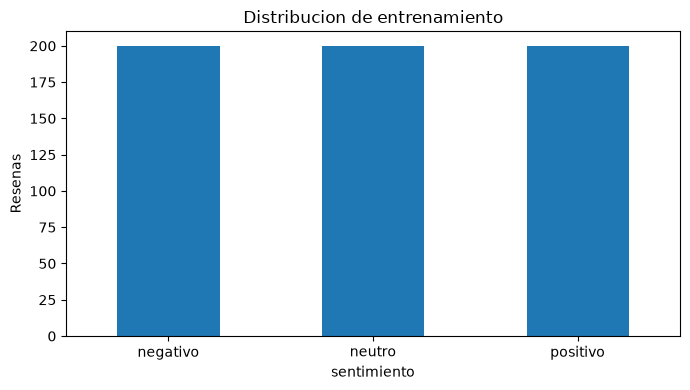

In [2]:
fig, ax = plt.subplots(figsize=(7,4))
df.sentimiento.value_counts().reindex(['negativo','neutro','positivo']).plot.bar(ax=ax, rot=0)
ax.set(title='Distribucion de entrenamiento', ylabel='Resenas')
plt.tight_layout()
plt.show()

count    600.00
mean      31.48
std       24.65
min        3.00
25%       15.00
50%       25.00
75%       38.25
max      203.00
              mean  median  min  max
sentimiento                         
negativo     33.90    25.0    6  203
neutro       31.84    26.0    3  186
positivo     28.70    23.0    5  161


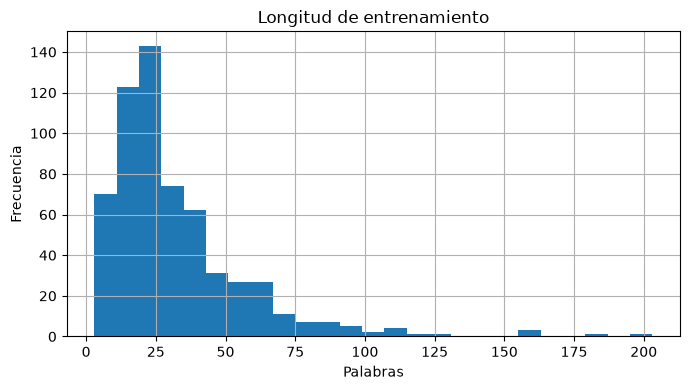

In [3]:
longitudes = df.texto.str.split().str.len()
print(longitudes.describe().round(2).to_string())
print(df.assign(palabras=longitudes).groupby('sentimiento').palabras.agg(['mean','median','min','max']).round(2).to_string())
fig, ax = plt.subplots(figsize=(7,4))
longitudes.hist(bins=25, ax=ax)
ax.set(title='Longitud de entrenamiento', xlabel='Palabras', ylabel='Frecuencia')
plt.tight_layout()
plt.show()

[('que', 657), ('muy', 277), ('para', 274), ('pero', 243), ('con', 188), ('bien', 176), ('los', 175), ('las', 160), ('por', 156), ('calidad', 154), ('una', 134), ('más', 130), ('producto', 103), ('como', 101), ('buena', 94), ('del', 88), ('precio', 81), ('son', 76), ('poco', 75), ('tiene', 62)]


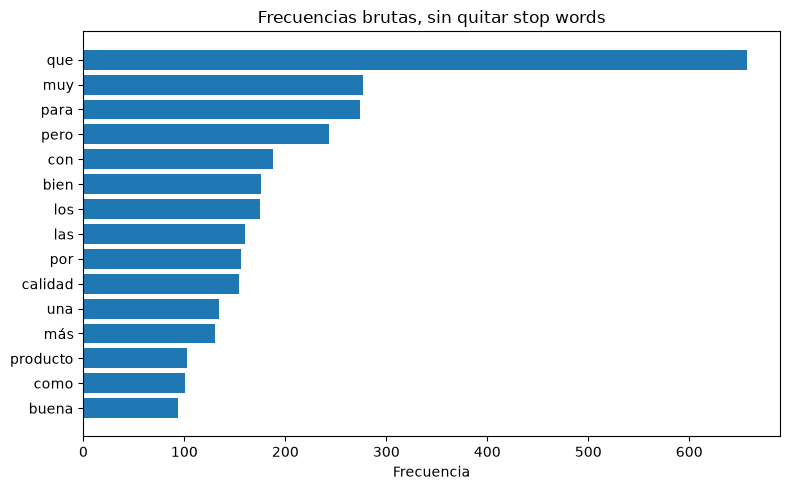

In [4]:
tokens = Counter(w for t in df.texto for w in re.findall(r'\b[^\W\d_]{3,}\b', t.lower()))
print(tokens.most_common(20))
fig, ax = plt.subplots(figsize=(8,5))
f = tokens.most_common(15)[::-1]
ax.barh([w for w,n in f], [n for w,n in f])
ax.set(title='Frecuencias brutas, sin quitar stop words', xlabel='Frecuencia')
plt.tight_layout()
plt.show()

In [5]:
print('Interpretacion: muestra balanceada por diseno; no necesita remuestreo adicional.')
print('Longitud tipica (mediana):', longitudes.median(), 'palabras; media:', round(longitudes.mean(),2))
print('Las palabras funcionales frecuentes justifican comparar el filtrado compartido de NLP.')
print('Las tres estrellas aproximan neutralidad: pueden contener valoraciones mixtas.')
print('Bigramas pueden representar negaciones locales; su aporte se decide solo por CV.')

Interpretacion: muestra balanceada por diseno; no necesita remuestreo adicional.
Longitud tipica (mediana): 25.0 palabras; media: 31.48
Las palabras funcionales frecuentes justifican comparar el filtrado compartido de NLP.
Las tres estrellas aproximan neutralidad: pueden contener valoraciones mixtas.
Bigramas pueden representar negaciones locales; su aporte se decide solo por CV.


## Comparaciones de NLP y modelos
Mismos tres folds estratificados y semilla 42. Resultados de validacion, sin seleccionar por test.

In [6]:
resultados = pd.read_csv(ROOT / 'resultados_finales_kelly_entrega/comparacion_modelos.csv')
print(resultados[['modelo','preprocesamiento','ngramas','hiperparametro','f1_macro_cv','desviacion_cv']].to_string(index=False))

             modelo preprocesamiento              ngramas  hiperparametro  f1_macro_cv  desviacion_cv
Regresión logística         stemming unigramas_y_bigramas             0.5     0.596220        0.01663
Regresión logística         stemming unigramas_y_bigramas             1.5     0.593920        0.00737
Regresión logística         stemming            unigramas             0.5     0.592420        0.01212
Regresión logística     lematizacion unigramas_y_bigramas             1.5     0.590890        0.01179
Regresión logística         stemming            unigramas             1.5     0.590660        0.01814
Regresión logística     lematizacion unigramas_y_bigramas             0.5     0.589560        0.02273
Regresión logística     lematizacion            unigramas             0.5     0.574770        0.02309
Regresión logística     lematizacion            unigramas             1.5     0.572150        0.02279
        Naive Bayes         stemming unigramas_y_bigramas             1.0     0.56